# June 2019 event -- consolidated T28-T38 per-task diagnostic plots

Reproduces every per-task diagnostic PNG the original October-anchored T28-T38
manual-check notebooks produced under `results/actual_data/`, now for the corrected
June 2019 event, saved under `result/` with the SAME filenames. Every formula/
threshold/weight is reused EXACTLY from the already-approved `iste/` modules -- this
notebook computes nothing new scientifically, it only re-points each already-approved
diagnostic at the June particle history instead of the October one.

**Efficiency note (not a scientific change):** the original T28-T38 notebooks were
each independent and re-swept the real particle history from scratch, often several
times per notebook (T33 alone re-swept it 3 times). This consolidated notebook
computes each EXPENSIVE shared quantity (the full candidate+support-grid sweep, the
per-timestamp cloud stats) ONCE and reuses it across every section that needs it --
the exact same `iste.*` function calls and values, just not recomputed redundantly.

In [1]:
import os, sys, time, json as _json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import Candidate, CoreRegion, CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index, project_to_local_metres
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_diagnostics import compute_diagnostics_table
from iste.phase3_normalization import normalize_support_grid, DEFAULT_PERCENTILE
from iste.phase3_initial_bias import compute_timestamp_cloud_stats, compute_initial_bias_influence, DEFAULT_K
from iste.phase3_persistence import track_candidate_persistence
from iste.phase3_convergence import compute_convergence_scores_for_candidates, ConvergenceWeights
from iste.phase3_dispersion import compute_dispersion_aware_score
from iste.phase3_screening import compute_screening_scores_for_candidates
from iste.phase3_composite import DEFAULT_WEIGHTS, CompositeWeights, compute_source_score, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates
from iste.phase3_uncertainty import (
    DEFAULT_TOTAL_TIMESTAMPS, DEFAULT_SPATIAL_PERCENTILE, BootstrapConfig,
    compute_cluster_uncertainty_table, run_bootstrap_stability, diagnose_uncertainty_vs_age,
)

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

## 0. Load the June 2019 particle history + observation (shared by every section below)

In [2]:
history_path = os.path.join(RESULT_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)
def _none_if_empty(arr):
    return None if arr.size == 0 else arr
records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
assert len(grid) == 73
print(f"loaded {records.n_records} June-2019 real rows; analysis grid: {len(grid)} timestamps, T0={grid[0]}, T72={grid[-1]}")

spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)
print(f"support/candidate-search grid: {len(support_lat_grid)} x {len(support_lon_grid)} points")

loaded 240024 June-2019 real rows; analysis grid: 73 timestamps, T0=2019-06-14T20:35:58.000000000, T72=2019-06-11T20:35:58.000000000
support/candidate-search grid: 163 x 157 points


## 1. Shared expensive sweep: candidates + support grids + cloud stats (computed ONCE)

Reused by T31/T32/T33/T34/T36/T37/T38 below -- identical `iste.*` calls the original
separate notebooks each performed independently (often more than once per notebook).

In [3]:
t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
cloud_stats_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
    cloud_stats_by_t_s[np.datetime64(t_s, "ns")] = compute_timestamp_cloud_stats(records, t_s)
t1 = time.time()
print(f"regenerated {len(all_candidates)} June-2019 candidates + {len(support_grids_by_t_s)} support grids + cloud stats in {t1-t0:.1f}s")

hotspots_export = [
    {"candidate_id": c.candidate_id, "lat": c.y_peak, "lon": c.x_peak,
     "t_s": str(np.datetime_as_string(np.datetime64(c.t_s, "ns"), unit="s")),
     "support_score": c.support_score, "density_score": c.density_score,
     "weighted_support_score": c.weighted_support_score, "pixel_diversity_score": c.pixel_diversity_score}
    for c in all_candidates
]

regenerated 271 June-2019 candidates + 72 support grids + cloud stats in 219.4s


## T28 -- per-timestamp diagnostics on the real T0-T72 window

In [4]:
t0 = time.time()
t28_table = compute_diagnostics_table(
    records, grid,
    support_lat_grid=support_lat_grid, support_lon_grid=support_lon_grid,
    neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, support_config=support_config, extraction_config=extraction_config,
)
t1 = time.time()
print(f"T28: computed diagnostics for {len(t28_table)} timestamps in {t1-t0:.1f}s")
assert len(t28_table) == 73

T28: computed diagnostics for 73 timestamps in 184.8s


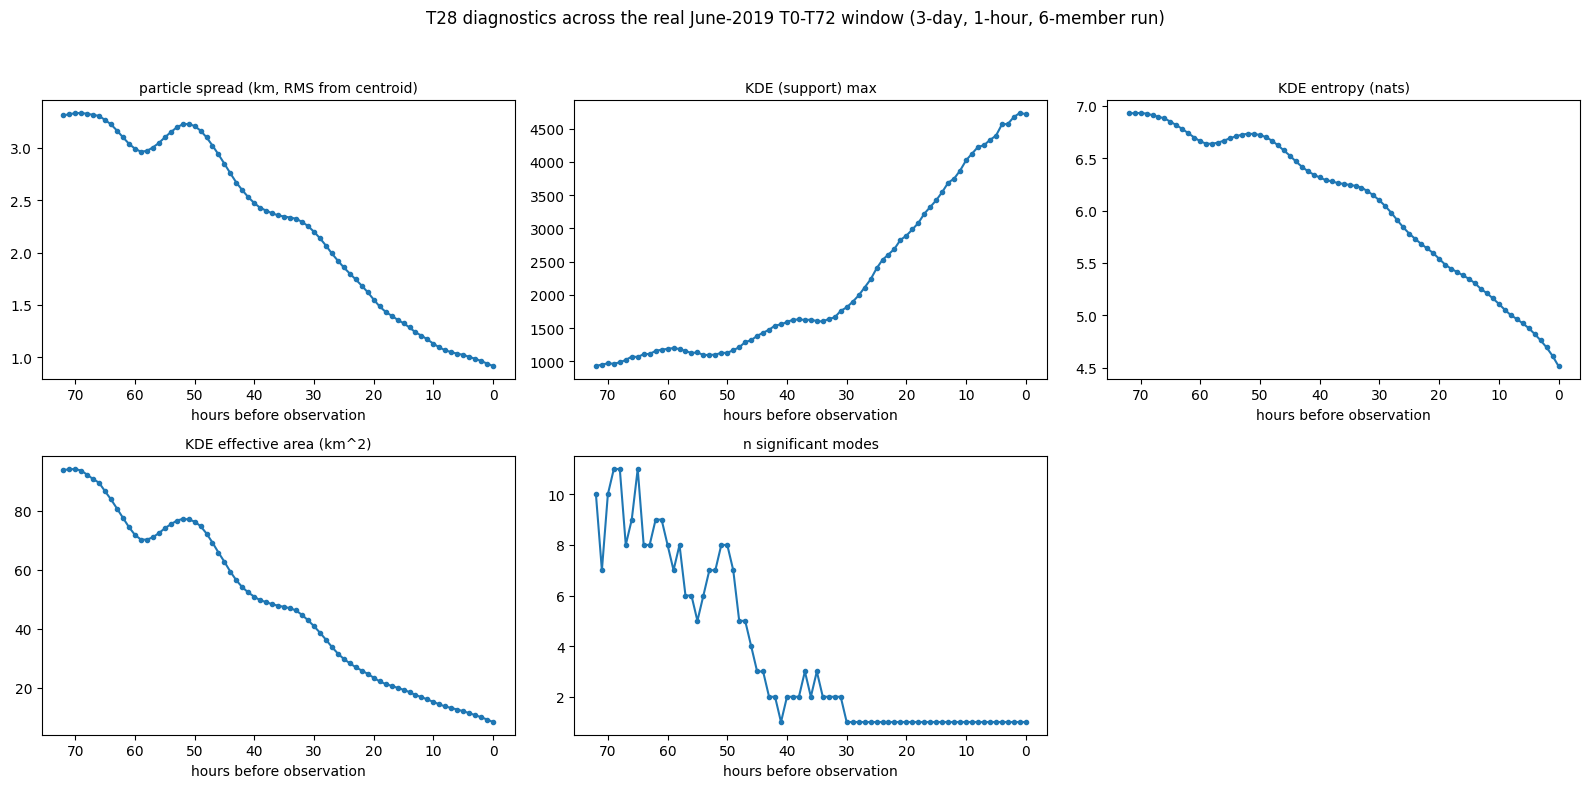

correlation(hours_before_obs, spatial_spread_km) = +0.978
correlation(hours_before_obs, kde_max) = -0.932


In [5]:
t28_hours = np.arange(len(t28_table))
t28_spread_km = np.array([d.spatial_spread_m / 1000 for d in t28_table])
t28_kde_max = np.array([d.kde_max for d in t28_table])
t28_entropy = np.array([d.kde_entropy for d in t28_table])
t28_eff_area_km2 = np.array([d.kde_effective_area_m2 / 1e6 for d in t28_table])
t28_n_modes = np.array([d.n_significant_modes for d in t28_table])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, (y, label) in zip(axes, [
    (t28_spread_km, "particle spread (km, RMS from centroid)"),
    (t28_kde_max, "KDE (support) max"),
    (t28_entropy, "KDE entropy (nats)"),
    (t28_eff_area_km2, "KDE effective area (km^2)"),
    (t28_n_modes, "n significant modes"),
]):
    ax.plot(t28_hours, y, "-o", markersize=3)
    ax.set_xlabel("hours before observation")
    ax.set_title(label, fontsize=10)
    ax.invert_xaxis()
axes[-1].axis("off")
fig.suptitle("T28 diagnostics across the real June-2019 T0-T72 window (3-day, 1-hour, 6-member run)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(os.path.join(RESULT_DIR, "T28_diagnostics_t0_t72.png"), dpi=100)
plt.show()

corr_spread = float(np.corrcoef(t28_hours, t28_spread_km)[0, 1])
corr_kde = float(np.corrcoef(t28_hours, t28_kde_max)[0, 1])
print(f"correlation(hours_before_obs, spatial_spread_km) = {corr_spread:+.3f}")
print(f"correlation(hours_before_obs, kde_max) = {corr_kde:+.3f}")

## T29 -- cross-time KDE normalization (8 representative sample timestamps)

In [6]:
t29_sample_hours = [0, 6, 12, 24, 36, 48, 60, 72]
t29_sample_t_s = [grid[h] for h in t29_sample_hours]
t29_raw_grids = {}
t29_norm_results = {}
for h, t_s in zip(t29_sample_hours, t29_sample_t_s):
    key = np.datetime64(t_s, "ns")
    grid_vals = support_grids_by_t_s.get(key)
    if grid_vals is None:
        slice_ = query_particle_slice(records, t_s)
        index = build_particle_neighborhood_index(slice_)
        support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
        grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    t29_raw_grids[h] = grid_vals
    t29_norm_results[h] = normalize_support_grid(grid_vals, t_s, percentile=DEFAULT_PERCENTILE)
print(f"T29: computed raw + normalized grids for {len(t29_sample_hours)} sample timestamps (T0 excluded from the main sweep, reused where available)")

T29: computed raw + normalized grids for 8 sample timestamps (T0 excluded from the main sweep, reused where available)


hours_before_obs  raw_kde_max  reference(p95)  normalized_max
               0      4719.00         4288.05           1.101
               6      4330.89         3516.09           1.232
              12      3749.51         2902.77           1.292
              24      2528.53         1944.64           1.300
              36      1627.94         1251.05           1.301
              48      1214.33          933.37           1.301
              60      1189.92          852.85           1.395
              72       931.25          671.71           1.386


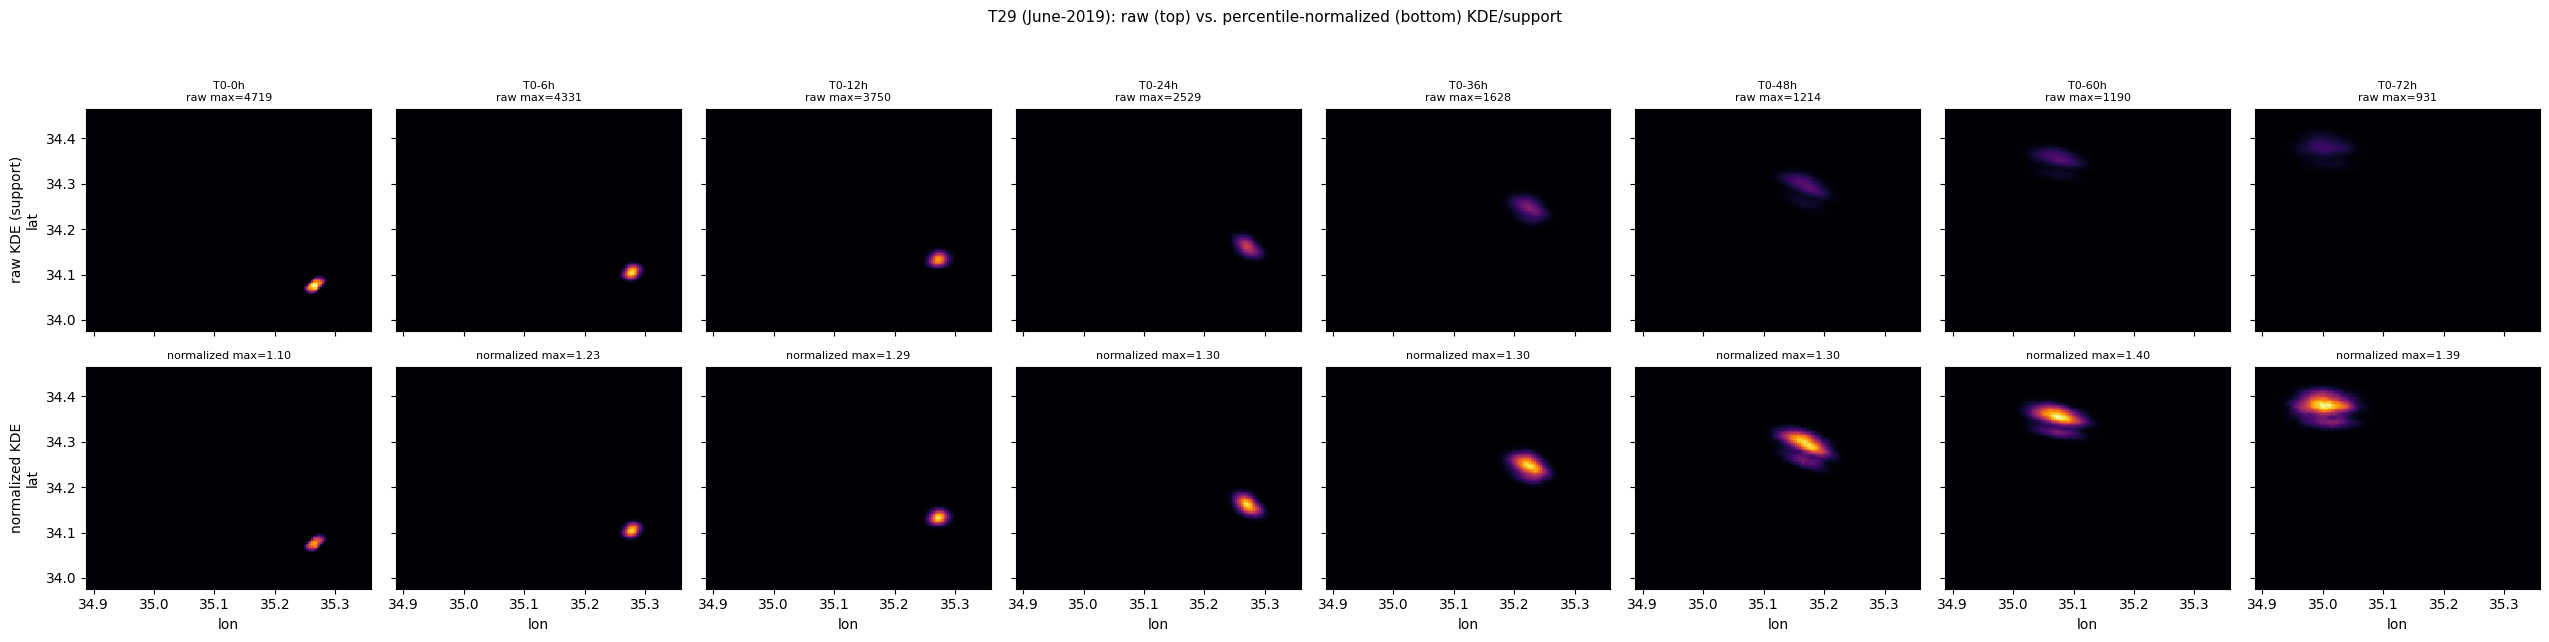

In [7]:
print(f"{'hours_before_obs':>16s} {'raw_kde_max':>12s} {'reference(p95)':>15s} {'normalized_max':>15s}")
for h in t29_sample_hours:
    r = t29_norm_results[h]
    print(f"{h:>16d} {r.raw_max:>12.2f} {r.reference_value:>15.2f} {r.normalized_max:>15.3f}")

fig, axes = plt.subplots(2, len(t29_sample_hours), figsize=(3.2 * len(t29_sample_hours), 6.5), sharex=True, sharey=True)
raw_vmax = max(t29_raw_grids[h].max() for h in t29_sample_hours)
norm_vmax = max(np.nanmax(t29_norm_results[h].normalized_grid) for h in t29_sample_hours)
for col, h in enumerate(t29_sample_hours):
    ax = axes[0, col]
    ax.pcolormesh(support_lon_grid, support_lat_grid, t29_raw_grids[h], shading="auto", cmap="inferno", vmin=0, vmax=raw_vmax)
    ax.set_title(f"T0-{h}h\nraw max={t29_raw_grids[h].max():.0f}", fontsize=8)
    ax = axes[1, col]
    ax.pcolormesh(support_lon_grid, support_lat_grid, t29_norm_results[h].normalized_grid, shading="auto", cmap="inferno", vmin=0, vmax=norm_vmax)
    ax.set_title(f"normalized max={t29_norm_results[h].normalized_max:.2f}", fontsize=8)
    ax.set_xlabel("lon")
axes[0, 0].set_ylabel("raw KDE (support)\nlat")
axes[1, 0].set_ylabel("normalized KDE\nlat")
fig.suptitle("T29 (June-2019): raw (top) vs. percentile-normalized (bottom) KDE/support", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULT_DIR, "T29_raw_vs_normalized_kde.png"), dpi=100)
plt.show()

## T30 -- Mahalanobis/dispersion-relative initial-condition influence

In [8]:
n_nan_t30 = 0
t30_rows = []
for h in hotspots_export:
    t_s = np.datetime64(h["t_s"], "ns")
    stats = cloud_stats_by_t_s[t_s]
    result = compute_initial_bias_influence(stats, h["lat"], h["lon"], k=DEFAULT_K)
    age_hours = float((t_obs - t_s) / np.timedelta64(1, "h"))
    t30_rows.append((h["candidate_id"], age_hours, result))
n_nan_t30 = sum(1 for _, _, r in t30_rows if np.isnan(r.influence))
print(f"T30: computed influence for {len(t30_rows)} June-2019 candidates ({n_nan_t30} NaN -- degenerate-covariance timestamps)")

t30_valid = [(cid, age, r) for cid, age, r in t30_rows if not np.isnan(r.influence)]
t30_ages = np.array([a for _, a, _ in t30_valid])
t30_influences = np.array([r.influence for _, _, r in t30_valid])
t30_mdists = np.array([r.mahalanobis_distance for _, _, r in t30_valid])
corr_age_influence = float(np.corrcoef(t30_ages, t30_influences)[0, 1])
corr_age_mdist = float(np.corrcoef(t30_ages, t30_mdists)[0, 1])
print(f"correlation(age_hours, influence) = {corr_age_influence:+.3f}")
print(f"correlation(age_hours, mahalanobis_distance) = {corr_age_mdist:+.3f}")

T30: computed influence for 271 June-2019 candidates (0 NaN -- degenerate-covariance timestamps)
correlation(age_hours, influence) = -0.579
correlation(age_hours, mahalanobis_distance) = +0.516


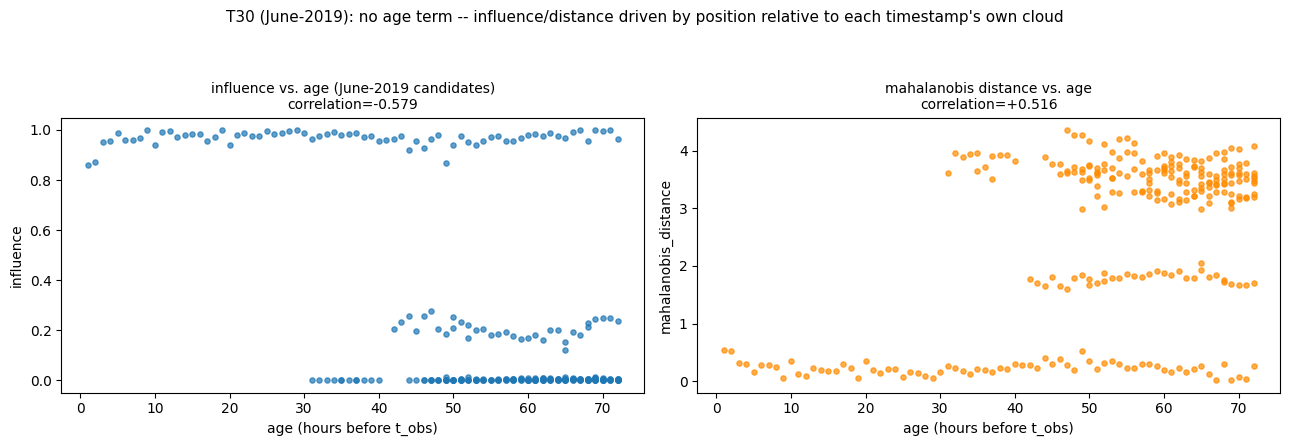

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(t30_ages, t30_influences, s=14, alpha=0.7)
axes[0].set_xlabel("age (hours before t_obs)"); axes[0].set_ylabel("influence")
axes[0].set_title(f"influence vs. age (June-2019 candidates)\ncorrelation={corr_age_influence:+.3f}", fontsize=10)
axes[1].scatter(t30_ages, t30_mdists, s=14, alpha=0.7, color="darkorange")
axes[1].set_xlabel("age (hours before t_obs)"); axes[1].set_ylabel("mahalanobis_distance")
axes[1].set_title(f"mahalanobis distance vs. age\ncorrelation={corr_age_mdist:+.3f}", fontsize=10)
fig.suptitle("T30 (June-2019): no age term -- influence/distance driven by position relative to each timestamp's own cloud", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(RESULT_DIR, "T30_initial_bias_influence.png"), dpi=100)
plt.show()

## T31 -- temporal persistence tracking

In [10]:
RUN_T_OBS = t_obs  # June-2019: the TRUE observation timestamp (no October workaround)
t31_candidates = []
for h in hotspots_export:
    t_s = np.datetime64(h["t_s"], "ns")
    t31_candidates.append(Candidate(
        candidate_id=h["candidate_id"], x_peak=h["lon"], y_peak=h["lat"], t_s=t_s,
        core_region=CoreRegion(center_lat=h["lat"], center_lon=h["lon"], radius_m=1000.0),
        support_score=h["support_score"], density_score=h["density_score"],
        weighted_support_score=h["weighted_support_score"], pixel_diversity_score=h["pixel_diversity_score"],
        peak_support_features=None,
    ))
tracks = track_candidate_persistence(t31_candidates)
print(f"T31: {len(t31_candidates)} June-2019 candidates -> {len(tracks)} persistence tracks")
n_assigned = sum(t.persistence_count for t in tracks)
assert n_assigned == len(t31_candidates)

T31: 271 June-2019 candidates -> 37 persistence tracks


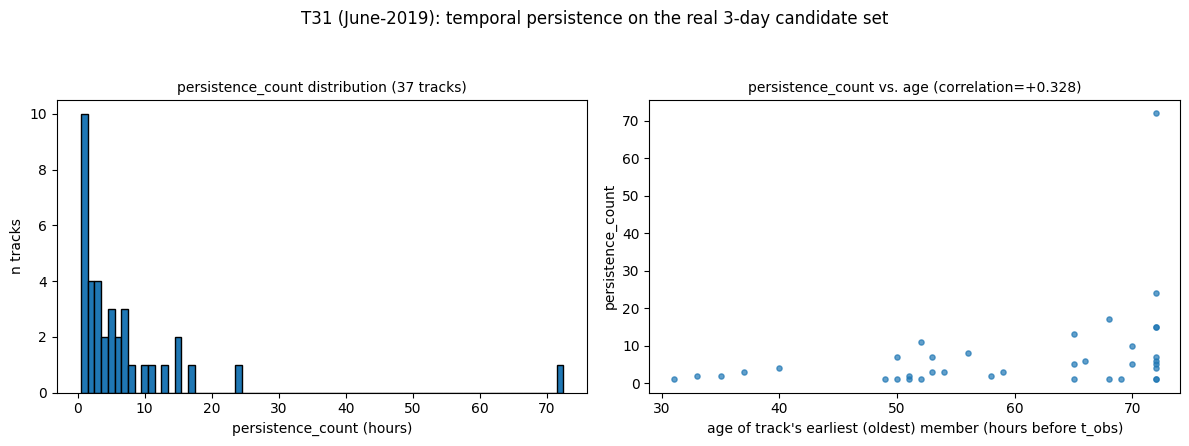

In [11]:
counts = np.array([t.persistence_count for t in tracks])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(counts, bins=np.arange(1, counts.max() + 2) - 0.5, edgecolor="black")
axes[0].set_xlabel("persistence_count (hours)"); axes[0].set_ylabel("n tracks")
axes[0].set_title(f"persistence_count distribution ({len(tracks)} tracks)", fontsize=10)

ages_of_earliest = np.array([float((RUN_T_OBS - t.earliest_t_s) / np.timedelta64(1, "h")) for t in tracks])
axes[1].scatter(ages_of_earliest, counts, s=14, alpha=0.7)
axes[1].set_xlabel("age of track's earliest (oldest) member (hours before t_obs)")
axes[1].set_ylabel("persistence_count")
corr_t31 = float(np.corrcoef(ages_of_earliest, counts)[0, 1])
axes[1].set_title(f"persistence_count vs. age (correlation={corr_t31:+.3f})", fontsize=10)
fig.suptitle("T31 (June-2019): temporal persistence on the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(os.path.join(RESULT_DIR, "T31_persistence_tracks.png"), dpi=100)
plt.show()

longest June-2019 track: track0000, persistence_count=72, duration=71.0h, continuity=1.000


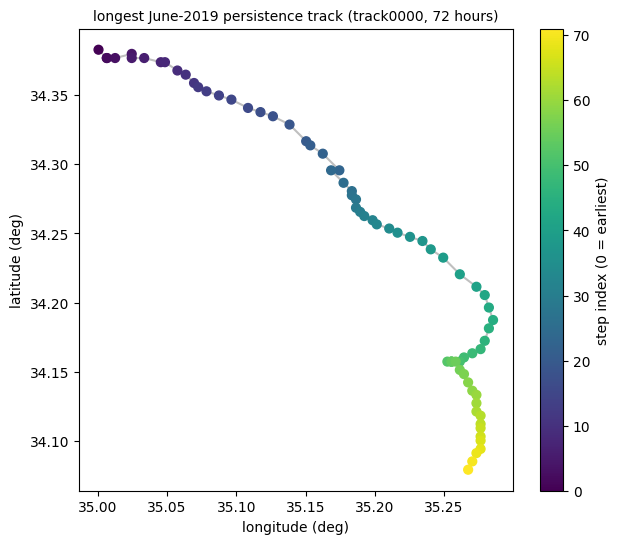

In [12]:
longest = max(tracks, key=lambda t: t.persistence_count)
print(f"longest June-2019 track: {longest.track_id}, persistence_count={longest.persistence_count}, "
      f"duration={longest.persistence_duration_hours}h, continuity={longest.temporal_continuity():.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(longest.lon_list, longest.lat_list, c=range(len(longest.lon_list)), cmap="viridis", s=40)
ax.plot(longest.lon_list, longest.lat_list, "-", color="gray", alpha=0.5, zorder=0)
fig.colorbar(sc, ax=ax, label="step index (0 = earliest)")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"longest June-2019 persistence track ({longest.track_id}, {longest.persistence_count} hours)", fontsize=10)
fig.savefig(os.path.join(RESULT_DIR, "T31_longest_track.png"), dpi=100)
plt.show()

adjacent (1h-apart) pairs: 71; displacement samples: 270
median=0.865km mean=1.271km p90=2.496km p99=6.962km max=8.738km


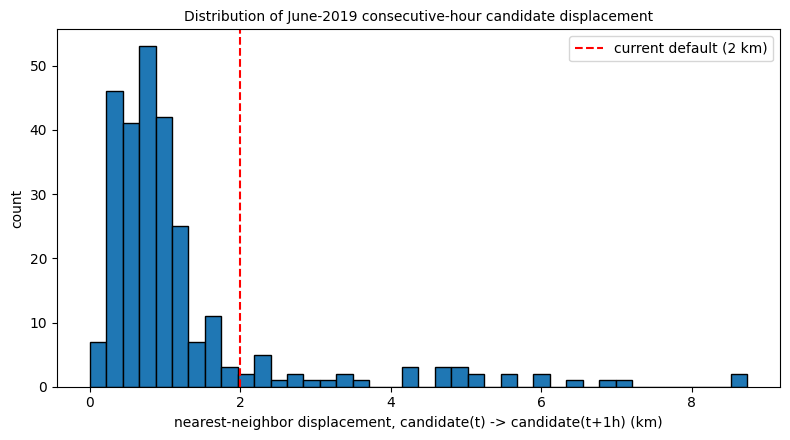

In [13]:
def _dist_m(lat1, lon1, lat2, lon2):
    x, y = project_to_local_metres(lat2, lon2, lat_ref=lat1, lon_ref=lon1)
    return float(np.sqrt(x[0] ** 2 + y[0] ** 2))

by_t_s_t31 = {}
for c in t31_candidates:
    by_t_s_t31.setdefault(c.t_s, []).append(c)
distinct_t_s_t31 = sorted(by_t_s_t31.keys())

nn_displacements_m = []
n_adjacent_pairs = 0
for i in range(len(distinct_t_s_t31) - 1):
    t_a, t_b = distinct_t_s_t31[i], distinct_t_s_t31[i + 1]
    if (t_b - t_a) != np.timedelta64(1, "h"):
        continue
    n_adjacent_pairs += 1
    cands_b = by_t_s_t31[t_b]
    for ca in by_t_s_t31[t_a]:
        nearest = min(_dist_m(ca.y_peak, ca.x_peak, cb.y_peak, cb.x_peak) for cb in cands_b)
        nn_displacements_m.append(nearest)
nn_displacements_m = np.array(nn_displacements_m)
d_km = nn_displacements_m / 1000.0
print(f"adjacent (1h-apart) pairs: {n_adjacent_pairs}; displacement samples: {len(nn_displacements_m)}")
print(f"median={np.median(d_km):.3f}km mean={np.mean(d_km):.3f}km p90={np.percentile(d_km,90):.3f}km p99={np.percentile(d_km,99):.3f}km max={np.max(d_km):.3f}km")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(d_km, bins=40, edgecolor="black")
ax.axvline(2.0, color="red", linestyle="--", label="current default (2 km)")
ax.set_xlabel("nearest-neighbor displacement, candidate(t) -> candidate(t+1h) (km)")
ax.set_ylabel("count")
ax.set_title("Distribution of June-2019 consecutive-hour candidate displacement", fontsize=10)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T31_displacement_distribution.png"), dpi=100)
plt.show()

n steps=71 max=1731.3m mean=737.0m total_path=52.33km


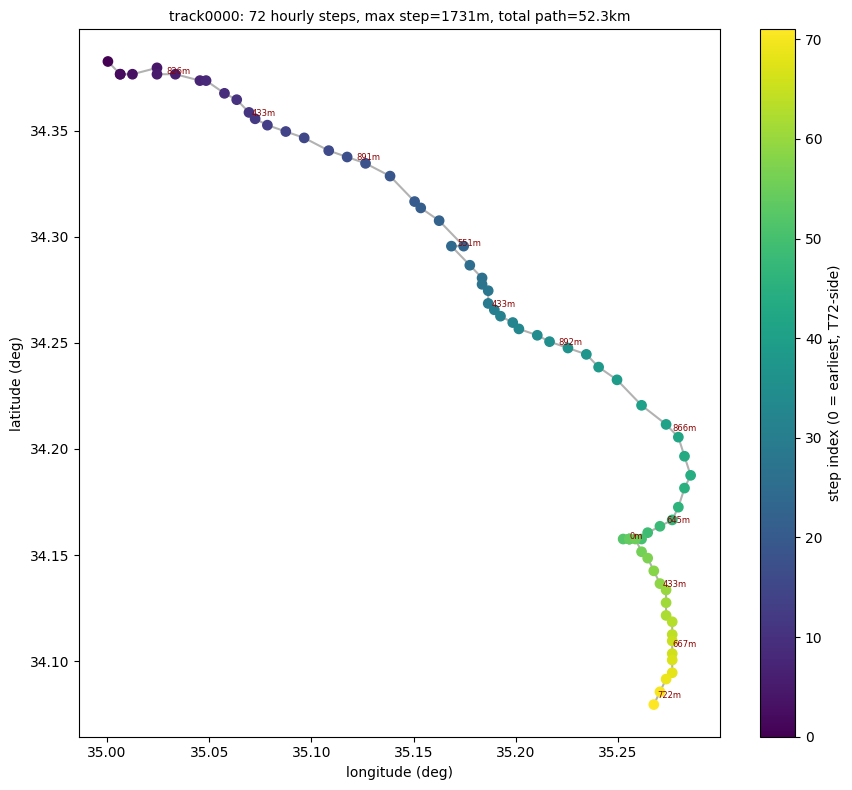

In [14]:
step_distances_m = []
for i in range(1, len(longest.t_s_list)):
    d = _dist_m(longest.lat_list[i-1], longest.lon_list[i-1], longest.lat_list[i], longest.lon_list[i])
    step_distances_m.append(d)
step_distances_m = np.array(step_distances_m)
print(f"n steps={len(step_distances_m)} max={step_distances_m.max():.1f}m mean={step_distances_m.mean():.1f}m "
      f"total_path={step_distances_m.sum()/1000:.2f}km")

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(longest.lon_list, longest.lat_list, c=range(len(longest.lon_list)), cmap="viridis", s=45, zorder=3)
ax.plot(longest.lon_list, longest.lat_list, "-", color="gray", alpha=0.6, zorder=1)
fig.colorbar(sc, ax=ax, label="step index (0 = earliest, T72-side)")
for i in range(1, len(longest.lon_list)):
    if i % 6 == 0 or i == len(longest.lon_list) - 1:
        mx = (longest.lon_list[i-1] + longest.lon_list[i]) / 2
        my = (longest.lat_list[i-1] + longest.lat_list[i]) / 2
        ax.annotate(f"{step_distances_m[i-1]:.0f}m", (mx, my), fontsize=6, color="darkred")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"{longest.track_id}: {longest.persistence_count} hourly steps, "
             f"max step={step_distances_m.max():.0f}m, total path={step_distances_m.sum()/1000:.1f}km", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T31_longest_track_annotated.png"), dpi=110)
plt.show()

## T32 -- spatial convergence scoring

In [15]:
t32_tracks = track_candidate_persistence(all_candidates)
convergence_scores = compute_convergence_scores_for_candidates(records, all_candidates, persistence_tracks=t32_tracks)
print(f"T32: computed convergence scores for {len(convergence_scores)} June-2019 candidates")

raw_density_t32 = np.array([s.particle_count for s in convergence_scores])
convergence_vals = np.array([s.convergence_score for s in convergence_scores])
corr_t32 = float(np.corrcoef(raw_density_t32, convergence_vals)[0, 1])
print(f"correlation(raw particle count, convergence_score) = {corr_t32:+.3f}")

T32: computed convergence scores for 271 June-2019 candidates
correlation(raw particle count, convergence_score) = +0.887


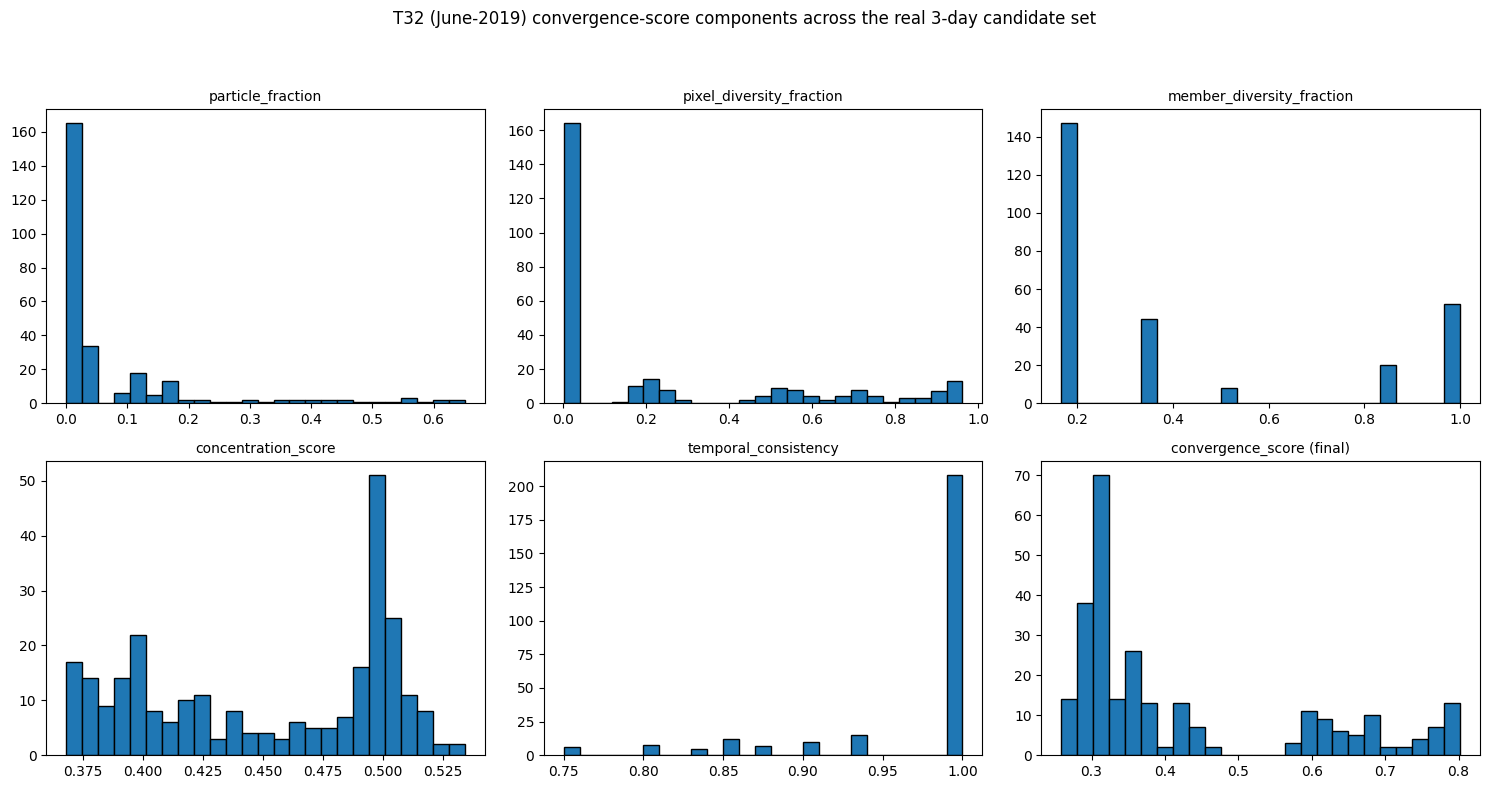

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
components = [
    ([s.particle_fraction for s in convergence_scores], "particle_fraction"),
    ([s.pixel_diversity_fraction for s in convergence_scores], "pixel_diversity_fraction"),
    ([s.member_diversity_fraction for s in convergence_scores], "member_diversity_fraction"),
    ([s.concentration_score for s in convergence_scores], "concentration_score"),
    ([s.temporal_consistency if s.temporal_consistency is not None else np.nan for s in convergence_scores], "temporal_consistency"),
    ([s.convergence_score for s in convergence_scores], "convergence_score (final)"),
]
for ax, (vals, title) in zip(axes.ravel(), components):
    ax.hist(vals, bins=25, edgecolor="black")
    ax.set_title(title, fontsize=10)
fig.suptitle("T32 (June-2019) convergence-score components across the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULT_DIR, "T32_convergence_components.png"), dpi=100)
plt.show()

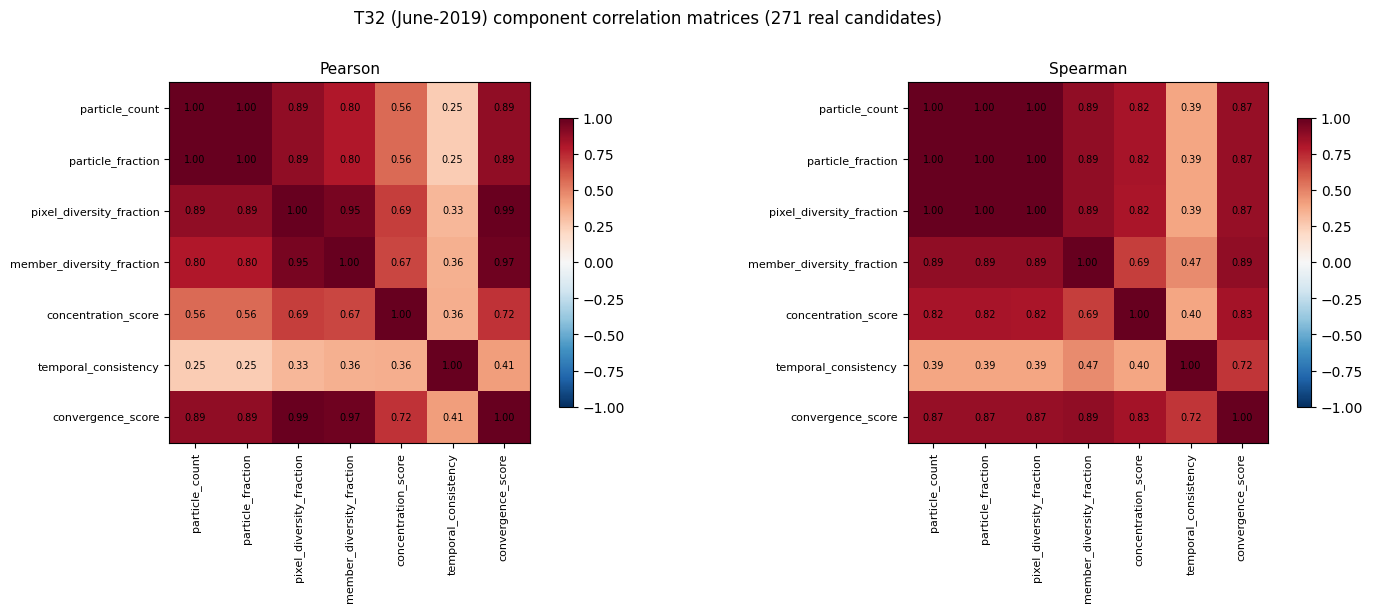

In [17]:
t32_df = pd.DataFrame([dict(
    candidate_id=s.candidate_id, particle_count=s.particle_count, particle_fraction=s.particle_fraction,
    pixel_diversity_fraction=s.pixel_diversity_fraction, member_diversity_fraction=s.member_diversity_fraction,
    concentration_score=s.concentration_score,
    temporal_consistency=s.temporal_consistency if s.temporal_consistency is not None else np.nan,
    convergence_score=s.convergence_score,
) for s in convergence_scores])
cols_t32 = ["particle_count", "particle_fraction", "pixel_diversity_fraction",
            "member_diversity_fraction", "concentration_score", "temporal_consistency", "convergence_score"]
pearson_corr = t32_df[cols_t32].corr(method="pearson")
spearman_corr = t32_df[cols_t32].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, corr, title in [(axes[0], pearson_corr, "Pearson"), (axes[1], spearman_corr, "Spearman")]:
    im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols_t32))); ax.set_xticklabels(cols_t32, rotation=90, fontsize=8)
    ax.set_yticks(range(len(cols_t32))); ax.set_yticklabels(cols_t32, fontsize=8)
    for i in range(len(cols_t32)):
        for j in range(len(cols_t32)):
            ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title, fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"T32 (June-2019) component correlation matrices ({len(t32_df)} real candidates)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULT_DIR, "T32_correlation_matrices.png"), dpi=100)
plt.show()

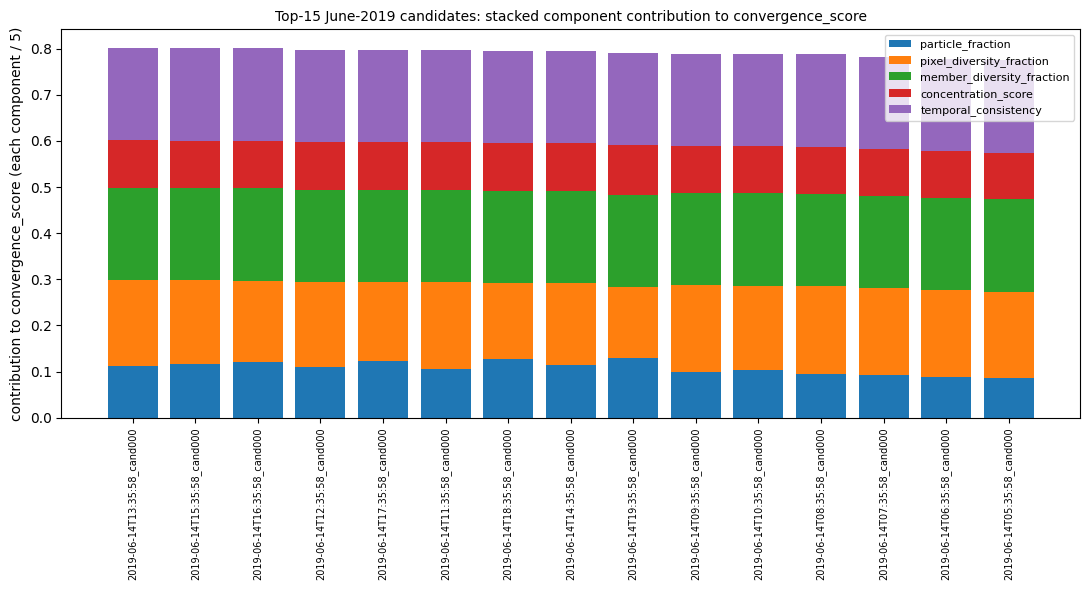

In [18]:
coef_t32 = 1.0 / 5.0
component_cols_t32 = ["particle_fraction", "pixel_diversity_fraction", "member_diversity_fraction", "concentration_score", "temporal_consistency"]
top15 = t32_df.sort_values("convergence_score", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(top15))
x = np.arange(len(top15))
for c in component_cols_t32:
    vals = top15[c].values * coef_t32
    ax.bar(x, vals, bottom=bottom, label=c)
    bottom += vals
ax.set_xticks(x); ax.set_xticklabels(top15["candidate_id"], rotation=90, fontsize=7)
ax.set_ylabel("contribution to convergence_score (each component / 5)")
ax.set_title("Top-15 June-2019 candidates: stacked component contribution to convergence_score", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T32_ablation_top15_stacked.png"), dpi=100)
plt.show()

## T33 -- dispersion-aware scoring (raw-vs-dispersion, anisotropy, empirical null -- one combined sweep)

In [19]:
from iste.kdtree_neighborhood import project_to_local_metres as _proj

def characterize_anisotropy(cov):
    eigvals, eigvecs = np.linalg.eigh(cov)
    lam2, lam1 = float(eigvals[0]), float(eigvals[1])
    axis_ratio = np.sqrt(lam1 / lam2) if lam2 > 0 else np.inf
    major_vec = eigvecs[:, 1]
    orientation_deg = float(np.degrees(np.arctan2(major_vec[1], major_vec[0])) % 180.0)
    det = lam1 * lam2
    return lam1, lam2, axis_ratio, orientation_deg, det

def p_within_r_isotropic(cov, r):
    sigma_iso_sq = float(np.trace(cov)) / 2.0
    return 1.0 - np.exp(-(r**2) / (2.0 * sigma_iso_sq))

def p_within_r_anisotropic_mc(cov, r, n_samples=200_000, seed=0):
    rng = np.random.default_rng(seed)
    samples = rng.multivariate_normal(mean=[0.0, 0.0], cov=cov, size=n_samples)
    dist = np.sqrt(samples[:, 0] ** 2 + samples[:, 1] ** 2)
    return float(np.mean(dist <= r))

def empirical_fraction_within_r(lat, lon, lat_ref, lon_ref, r):
    x, y = _proj(lat, lon, lat_ref=lat_ref, lon_ref=lon_ref)
    d = np.sqrt(x**2 + y**2)
    return float(np.mean(d <= r))

t0 = time.time()
t33_rows, t33_diag_rows, t33_emp_rows = [], [], []
for t_s in historical_timestamps:
    key = np.datetime64(t_s, "ns")
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == key]
    if not cands_here:
        continue
    top_candidate = max(cands_here, key=lambda c: c.support_score)
    cloud_stats = cloud_stats_by_t_s[key]
    disp = compute_dispersion_aware_score(top_candidate, cloud_stats, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M)
    hours_before_obs = float((t_obs - t_s) / np.timedelta64(1, "h"))
    t33_rows.append(dict(hours_before_obs=hours_before_obs, raw_density=top_candidate.density_score,
                          n_total=cloud_stats.n_particles, dispersion_aware_score=disp.dispersion_aware_score))

    if cloud_stats.covariance_state != "full_rank":
        continue
    lam1, lam2, axis_ratio, orientation_deg, det = characterize_anisotropy(cloud_stats.covariance_m2)
    p_iso = p_within_r_isotropic(cloud_stats.covariance_m2, NEIGHBORHOOD_RADIUS_M)
    p_aniso = p_within_r_anisotropic_mc(cloud_stats.covariance_m2, NEIGHBORHOOD_RADIUS_M, seed=42)
    slice_ = query_particle_slice(records, t_s)
    valid = slice_.valid
    p_empirical = empirical_fraction_within_r(slice_.lat[valid], slice_.lon[valid], cloud_stats.lat_ref, cloud_stats.lon_ref, NEIGHBORHOOD_RADIUS_M)
    n_total = cloud_stats.n_particles
    d_expected_iso = n_total * p_iso
    d_expected_aniso = n_total * p_aniso
    disp_score_iso = top_candidate.density_score / d_expected_iso if d_expected_iso > 0 else np.nan
    disp_score_aniso = top_candidate.density_score / d_expected_aniso if d_expected_aniso > 0 else np.nan
    t33_diag_rows.append(dict(hours_before_obs=hours_before_obs, raw_density=top_candidate.density_score, n_total=n_total,
        lam1=lam1, lam2=lam2, axis_ratio=axis_ratio, orientation_deg=orientation_deg, det=det,
        p_empirical=p_empirical, p_iso=p_iso, p_aniso=p_aniso, disp_score_iso=disp_score_iso, disp_score_aniso=disp_score_aniso))

    index = build_particle_neighborhood_index(slice_)
    positions = np.column_stack([index.x_m, index.y_m])
    local_counts = index._tree.query_ball_point(positions, NEIGHBORHOOD_RADIUS_M, return_length=True)
    d_expected_empirical_median = float(np.median(local_counts))
    empirical_null_score = top_candidate.density_score / d_expected_empirical_median if d_expected_empirical_median > 0 else np.nan
    t33_emp_rows.append(dict(hours_before_obs=hours_before_obs, d_actual=top_candidate.density_score,
        d_expected_gaussian=disp.expected_density, gaussian_score=disp.dispersion_aware_score,
        d_expected_empirical_median=d_expected_empirical_median, empirical_null_score=empirical_null_score))
t1 = time.time()
print(f"T33: combined sweep over {len(t33_rows)} timestamps in {t1-t0:.1f}s ({len(t33_diag_rows)} full-rank for anisotropy/empirical-null)")

T33: combined sweep over 72 timestamps in 42.4s (72 full-rank for anisotropy/empirical-null)


correlation(hours, raw_density)=-0.910  correlation(hours, dispersion_aware_score)=+0.854


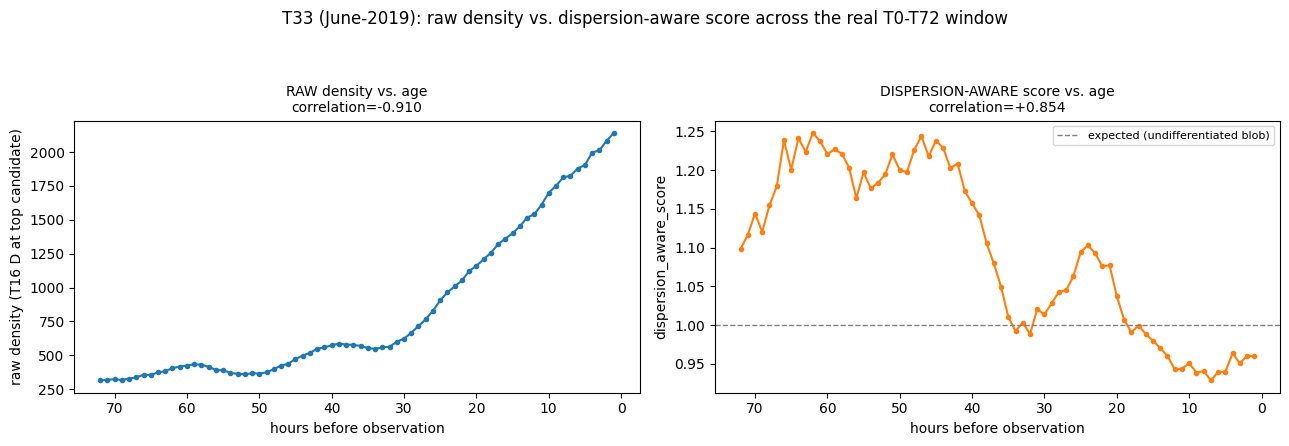

In [20]:
t33_hours = np.array([r["hours_before_obs"] for r in t33_rows])
t33_raw = np.array([r["raw_density"] for r in t33_rows])
t33_disp = np.array([r["dispersion_aware_score"] for r in t33_rows])
corr_raw_t33 = float(np.corrcoef(t33_hours, t33_raw)[0, 1])
corr_disp_t33 = float(np.corrcoef(t33_hours, t33_disp)[0, 1])
print(f"correlation(hours, raw_density)={corr_raw_t33:+.3f}  correlation(hours, dispersion_aware_score)={corr_disp_t33:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(t33_hours, t33_raw, "-o", markersize=3, color="tab:blue")
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("raw density (T16 D at top candidate)")
axes[0].set_title(f"RAW density vs. age\ncorrelation={corr_raw_t33:+.3f}", fontsize=10); axes[0].invert_xaxis()
axes[1].plot(t33_hours, t33_disp, "-o", markersize=3, color="tab:orange")
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1, label="expected (undifferentiated blob)")
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("dispersion_aware_score")
axes[1].set_title(f"DISPERSION-AWARE score vs. age\ncorrelation={corr_disp_t33:+.3f}", fontsize=10)
axes[1].invert_xaxis(); axes[1].legend(fontsize=8)
fig.suptitle("T33 (June-2019): raw density vs. dispersion-aware score across the real T0-T72 window", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(RESULT_DIR, "T33_dispersion_vs_raw.png"), dpi=100)
plt.show()

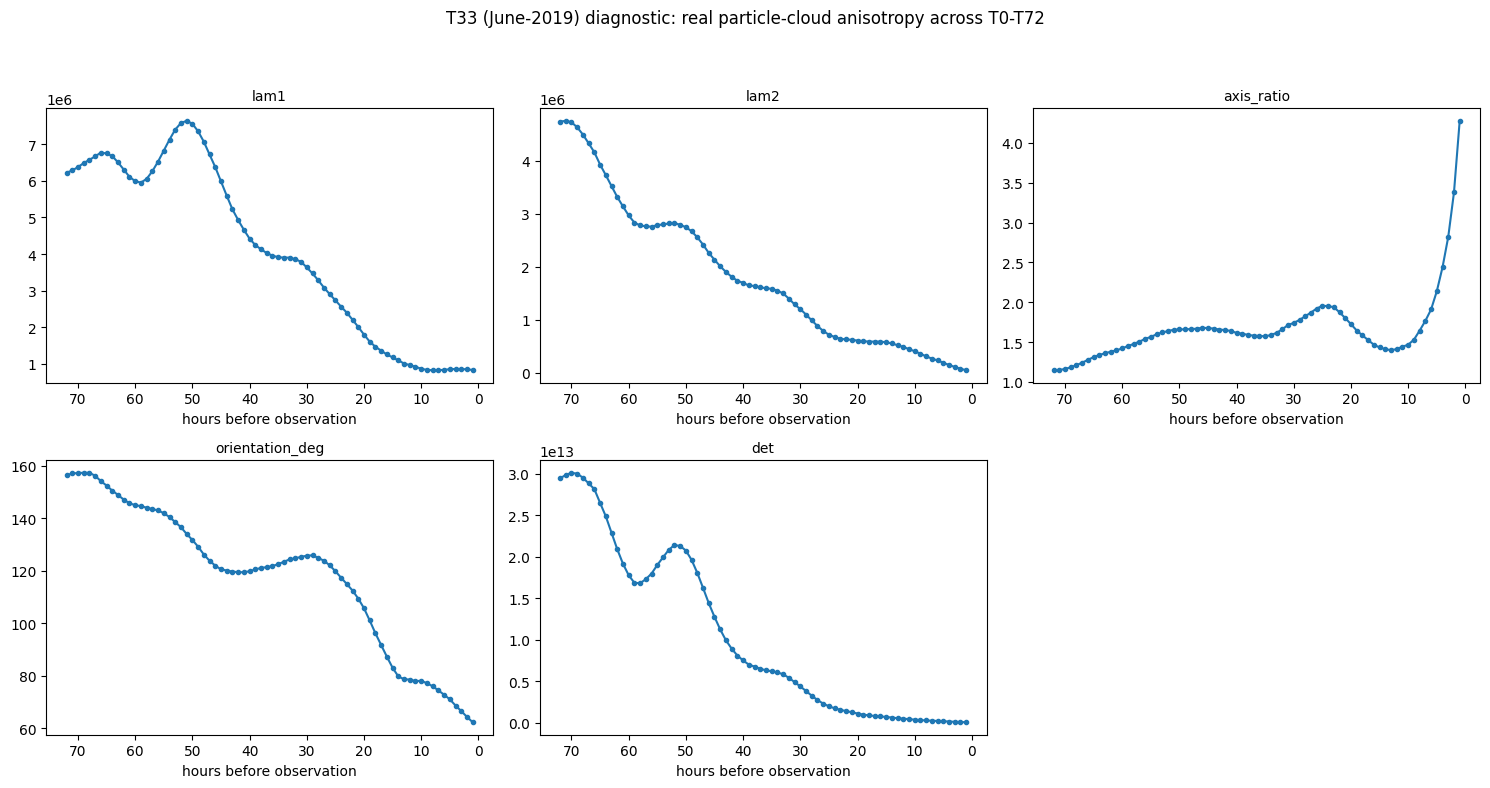

In [21]:
t33_diag_df = pd.DataFrame(t33_diag_rows)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["lam1", "lam2", "axis_ratio", "orientation_deg", "det"]):
    ax.plot(t33_diag_df["hours_before_obs"], t33_diag_df[col], "-o", markersize=3)
    ax.set_xlabel("hours before observation"); ax.set_title(col, fontsize=10)
    ax.invert_xaxis()
axes.ravel()[-1].axis("off")
fig.suptitle("T33 (June-2019) diagnostic: real particle-cloud anisotropy across T0-T72", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULT_DIR, "T33_anisotropy_characterization.png"), dpi=100)
plt.show()

isotropic model error MAE=0.0156  anisotropic model error MAE=0.0204
corr(age, disp_score_iso)=+0.854  corr(age, disp_score_aniso)=+0.906


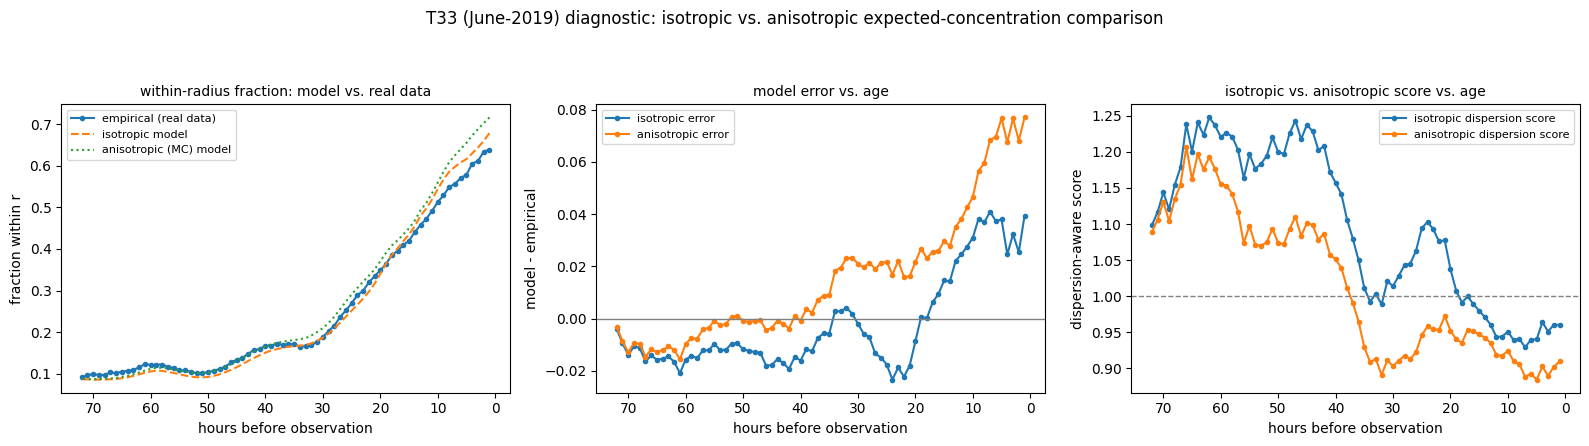

In [22]:
err_iso = t33_diag_df["p_iso"] - t33_diag_df["p_empirical"]
err_aniso = t33_diag_df["p_aniso"] - t33_diag_df["p_empirical"]
corr_iso_pearson = float(np.corrcoef(t33_diag_df["hours_before_obs"], t33_diag_df["disp_score_iso"])[0, 1])
corr_aniso_pearson = float(np.corrcoef(t33_diag_df["hours_before_obs"], t33_diag_df["disp_score_aniso"])[0, 1])
print(f"isotropic model error MAE={err_iso.abs().mean():.4f}  anisotropic model error MAE={err_aniso.abs().mean():.4f}")
print(f"corr(age, disp_score_iso)={corr_iso_pearson:+.3f}  corr(age, disp_score_aniso)={corr_aniso_pearson:+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(t33_diag_df["hours_before_obs"], t33_diag_df["p_empirical"], "-o", markersize=3, label="empirical (real data)")
axes[0].plot(t33_diag_df["hours_before_obs"], t33_diag_df["p_iso"], "--", label="isotropic model")
axes[0].plot(t33_diag_df["hours_before_obs"], t33_diag_df["p_aniso"], ":", label="anisotropic (MC) model")
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("fraction within r")
axes[0].set_title("within-radius fraction: model vs. real data", fontsize=10)
axes[0].legend(fontsize=8); axes[0].invert_xaxis()
axes[1].plot(t33_diag_df["hours_before_obs"], err_iso, "-o", markersize=3, label="isotropic error")
axes[1].plot(t33_diag_df["hours_before_obs"], err_aniso, "-o", markersize=3, label="anisotropic error")
axes[1].axhline(0, color="gray", linewidth=1)
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("model - empirical")
axes[1].set_title("model error vs. age", fontsize=10); axes[1].legend(fontsize=8); axes[1].invert_xaxis()
axes[2].plot(t33_diag_df["hours_before_obs"], t33_diag_df["disp_score_iso"], "-o", markersize=3, label="isotropic dispersion score")
axes[2].plot(t33_diag_df["hours_before_obs"], t33_diag_df["disp_score_aniso"], "-o", markersize=3, label="anisotropic dispersion score")
axes[2].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("dispersion-aware score")
axes[2].set_title("isotropic vs. anisotropic score vs. age", fontsize=10); axes[2].legend(fontsize=8); axes[2].invert_xaxis()
fig.suptitle("T33 (June-2019) diagnostic: isotropic vs. anisotropic expected-concentration comparison", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(RESULT_DIR, "T33_isotropic_vs_anisotropic.png"), dpi=100)
plt.show()

corr(age, gaussian_score)=+0.854  corr(age, empirical_null_score)=+0.964


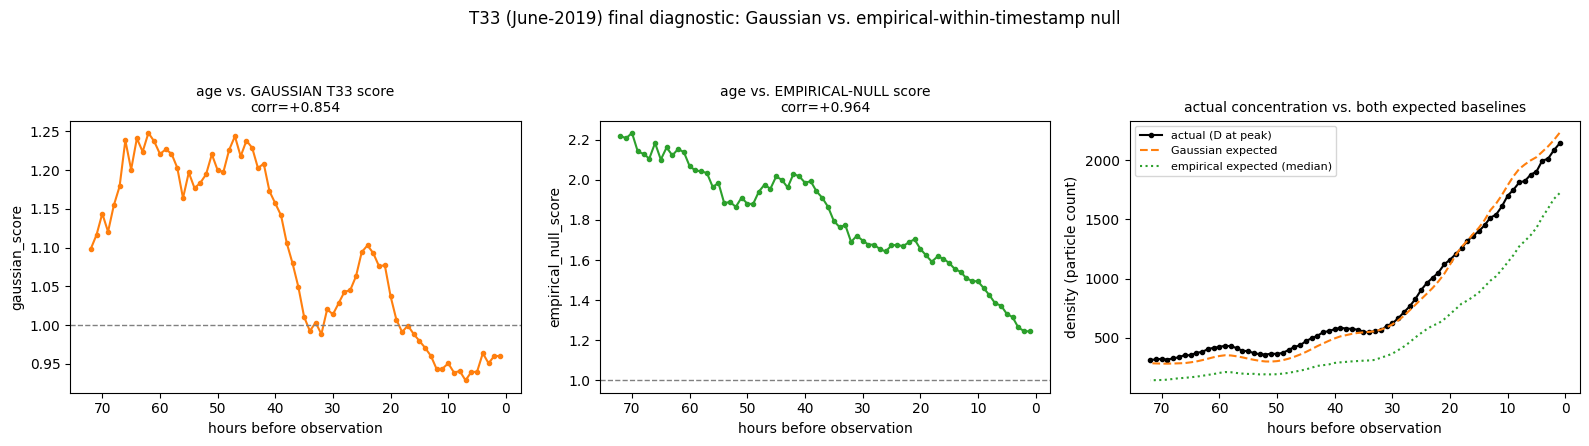

In [23]:
t33_emp_df = pd.DataFrame(t33_emp_rows)
corr_gauss_pearson = float(np.corrcoef(t33_emp_df["hours_before_obs"], t33_emp_df["gaussian_score"])[0, 1])
corr_emp_pearson = float(np.corrcoef(t33_emp_df["hours_before_obs"], t33_emp_df["empirical_null_score"])[0, 1])
print(f"corr(age, gaussian_score)={corr_gauss_pearson:+.3f}  corr(age, empirical_null_score)={corr_emp_pearson:+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(t33_emp_df["hours_before_obs"], t33_emp_df["gaussian_score"], "-o", markersize=3, color="tab:orange")
axes[0].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("hours before observation"); axes[0].set_ylabel("gaussian_score")
axes[0].set_title(f"age vs. GAUSSIAN T33 score\ncorr={corr_gauss_pearson:+.3f}", fontsize=10); axes[0].invert_xaxis()
axes[1].plot(t33_emp_df["hours_before_obs"], t33_emp_df["empirical_null_score"], "-o", markersize=3, color="tab:green")
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("empirical_null_score")
axes[1].set_title(f"age vs. EMPIRICAL-NULL score\ncorr={corr_emp_pearson:+.3f}", fontsize=10); axes[1].invert_xaxis()
axes[2].plot(t33_emp_df["hours_before_obs"], t33_emp_df["d_actual"], "-o", markersize=3, label="actual (D at peak)", color="black")
axes[2].plot(t33_emp_df["hours_before_obs"], t33_emp_df["d_expected_gaussian"], "--", label="Gaussian expected", color="tab:orange")
axes[2].plot(t33_emp_df["hours_before_obs"], t33_emp_df["d_expected_empirical_median"], ":", label="empirical expected (median)", color="tab:green")
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("density (particle count)")
axes[2].set_title("actual concentration vs. both expected baselines", fontsize=10)
axes[2].legend(fontsize=8); axes[2].invert_xaxis()
fig.suptitle("T33 (June-2019) final diagnostic: Gaussian vs. empirical-within-timestamp null", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(RESULT_DIR, "T33_empirical_null_diagnostic.png"), dpi=100)
plt.show()

## T34 -- screening-signal normalization

In [24]:
screening_scores = compute_screening_scores_for_candidates(all_candidates, support_grids_by_t_s)
n_nan_t34 = sum(1 for s in screening_scores if np.isnan(s.screening_score))
print(f"T34: computed screening scores for {len(screening_scores)} June-2019 candidates ({n_nan_t34} NaN)")

t34_ages = np.array([float((t_obs - s.t_s) / np.timedelta64(1, "h")) for s in screening_scores])
t34_raw = np.array([s.raw_support_score for s in screening_scores])
t34_screen = np.array([s.screening_score for s in screening_scores])
t34_valid = ~np.isnan(t34_screen)
corr_raw_t34 = float(np.corrcoef(t34_ages[t34_valid], t34_raw[t34_valid])[0, 1])
corr_screen_t34 = float(np.corrcoef(t34_ages[t34_valid], t34_screen[t34_valid])[0, 1])
print(f"correlation(age, raw_support_score)={corr_raw_t34:+.3f}  correlation(age, screening_score)={corr_screen_t34:+.3f}")

T34: computed screening scores for 271 June-2019 candidates (0 NaN)
correlation(age, raw_support_score)=-0.818  correlation(age, screening_score)=-0.538


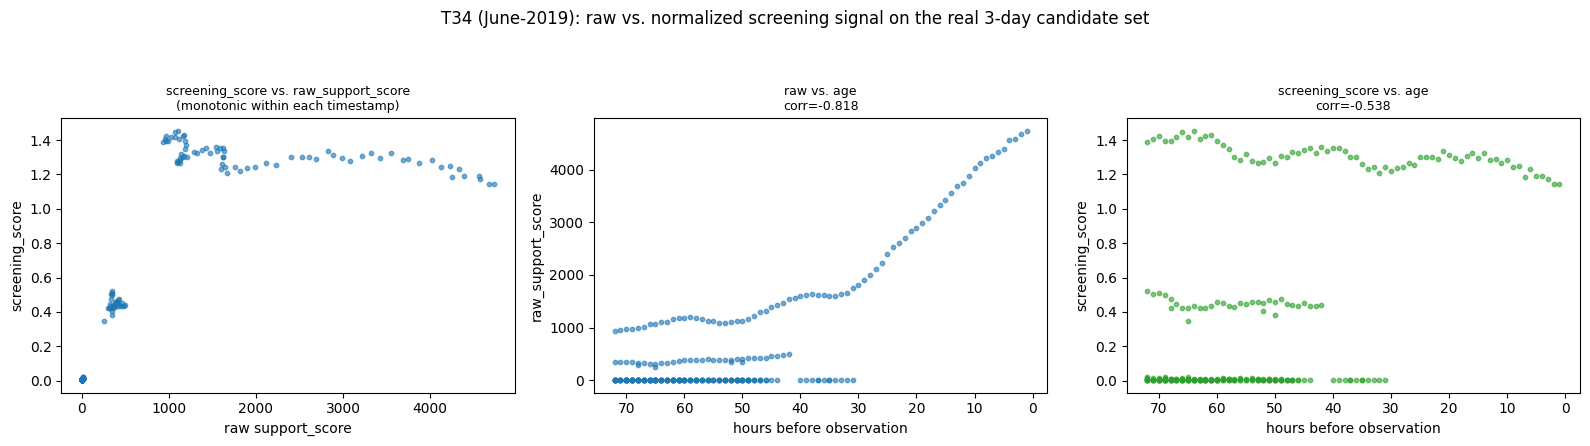

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(t34_raw, t34_screen, s=10, alpha=0.6)
axes[0].set_xlabel("raw support_score"); axes[0].set_ylabel("screening_score")
axes[0].set_title("screening_score vs. raw_support_score\n(monotonic within each timestamp)", fontsize=9)
axes[1].scatter(t34_ages[t34_valid], t34_raw[t34_valid], s=10, alpha=0.6, color="tab:blue")
axes[1].set_xlabel("hours before observation"); axes[1].set_ylabel("raw_support_score")
axes[1].set_title(f"raw vs. age\ncorr={corr_raw_t34:+.3f}", fontsize=9); axes[1].invert_xaxis()
axes[2].scatter(t34_ages[t34_valid], t34_screen[t34_valid], s=10, alpha=0.6, color="tab:green")
axes[2].set_xlabel("hours before observation"); axes[2].set_ylabel("screening_score")
axes[2].set_title(f"screening_score vs. age\ncorr={corr_screen_t34:+.3f}", fontsize=9); axes[2].invert_xaxis()
fig.suptitle("T34 (June-2019): raw vs. normalized screening signal on the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(os.path.join(RESULT_DIR, "T34_screening_normalization.png"), dpi=100)
plt.show()

## T36 -- composite multi-feature source score

T36: computed composite source scores for 271 June-2019 candidates in 139.6s
Spearman rank correlation (source_score vs. raw support_score): 0.8069


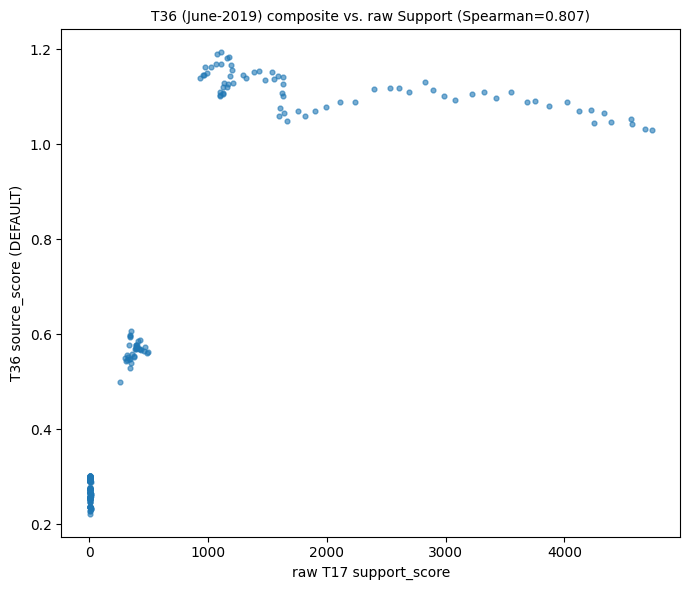

In [26]:
t0 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, weights=DEFAULT_WEIGHTS,
)
t1 = time.time()
print(f"T36: computed composite source scores for {len(default_scores)} June-2019 candidates in {t1-t0:.1f}s")

raw_support = {c.candidate_id: c.support_score for c in all_candidates}
composite = {s.candidate_id: s.source_score for s in default_scores}
raw_vals_t36 = [raw_support[cid] for cid in raw_support]
composite_vals_t36 = [composite[cid] for cid in raw_support]
rank_corr_t36 = spearmanr(raw_vals_t36, composite_vals_t36)
print(f"Spearman rank correlation (source_score vs. raw support_score): {rank_corr_t36.correlation:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(raw_vals_t36, composite_vals_t36, s=12, alpha=0.6)
ax.set_xlabel("raw T17 support_score"); ax.set_ylabel("T36 source_score (DEFAULT)")
ax.set_title(f"T36 (June-2019) composite vs. raw Support (Spearman={rank_corr_t36.correlation:.3f})", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T36_composite_vs_raw_support.png"), dpi=100)
plt.show()

### T36 dominant-track member-by-member diagnostic

In [27]:
scores_by_id_t36 = {s.candidate_id: s for s in default_scores}
dominant_track = max(t32_tracks, key=lambda t: t.persistence_count)
print(f"dominant track: {dominant_track.track_id}, {dominant_track.persistence_count} members")

candidates_by_id_t36 = {c.candidate_id: c for c in all_candidates}
track_candidates = [candidates_by_id_t36[cid] for cid in dominant_track.candidate_ids]

def _local_density_and_median(t_s):
    key = np.datetime64(t_s, "ns")
    slice_ = query_particle_slice(records, key)
    index = build_particle_neighborhood_index(slice_)
    positions = np.column_stack([index.x_m, index.y_m])
    local_counts = index._tree.query_ball_point(positions, NEIGHBORHOOD_RADIUS_M, return_length=True)
    return float(np.median(local_counts))

pop_median_density = {}
t36_rows = []
for c in track_candidates:
    t_s = np.datetime64(c.t_s, "ns")
    age_hours = float((t_obs - t_s) / np.timedelta64(1, "h"))
    r = scores_by_id_t36[c.candidate_id]
    cs = cloud_stats_by_t_s[t_s]
    if cs.covariance_state == "full_rank":
        lam1, lam2 = np.sort(np.linalg.eigvalsh(cs.covariance_m2))[::-1]
        det = float(lam1 * lam2)
    else:
        det = np.nan
    dr = compute_dispersion_aware_score(c, cs, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M)
    if t_s not in pop_median_density:
        pop_median_density[t_s] = _local_density_and_median(t_s)
    t36_rows.append(dict(
        candidate_id=c.candidate_id, age_hours=age_hours, raw_support=c.support_score,
        support_evidence=r.support_evidence, convergence_evidence=r.convergence_evidence,
        dispersion_evidence=r.dispersion_evidence, persistence_evidence=r.persistence_evidence,
        composite_score=r.source_score,
        contrib_support=r.effective_weights["support"] * r.support_evidence,
        contrib_persistence=r.effective_weights["persistence"] * r.persistence_evidence,
        contrib_convergence=r.effective_weights["convergence"] * r.convergence_evidence,
        contrib_dispersion=r.effective_weights["dispersion"] * r.dispersion_evidence,
        covariance_det=det, candidate_local_density=dr.particle_count_actual,
        population_median_local_density=pop_median_density[t_s],
        t33_expected_density=dr.expected_density, t33_dispersion_ratio=dr.dispersion_aware_score,
    ))
track_df = pd.DataFrame(t36_rows)
track_df["composite_rank"] = track_df["composite_score"].rank(ascending=False).astype(int)
track_df["empirical_ratio"] = track_df["candidate_local_density"] / track_df["population_median_local_density"]
print(f"built dominant-track diagnostic table for {len(track_df)} members")

dominant track: track0000, 72 members


built dominant-track diagnostic table for 72 members


In [28]:
t33_removed_weights = CompositeWeights(
    w_support=DEFAULT_WEIGHTS.w_support, w_persistence=DEFAULT_WEIGHTS.w_persistence,
    w_convergence=DEFAULT_WEIGHTS.w_convergence, w_dispersion=0.0, w_ais=DEFAULT_WEIGHTS.w_ais,
)
no_t33_scores = []
for c in track_candidates:
    r = scores_by_id_t36[c.candidate_id]
    components = {
        "support": (t33_removed_weights.w_support, r.support_evidence),
        "persistence": (t33_removed_weights.w_persistence, r.persistence_evidence),
        "convergence": (t33_removed_weights.w_convergence, r.convergence_evidence),
        "dispersion": (t33_removed_weights.w_dispersion, None),
        "ais": (t33_removed_weights.w_ais, r.ais_evidence),
        "initial_bias": (0.0, None), "persistence_count": (0.0, None),
    }
    from iste.phase3_ais import renormalize_weighted_mean
    no_t33_scores.append(renormalize_weighted_mean(list(components.values())))
track_df["composite_score_no_t33"] = no_t33_scores
print(f"Spearman(age, score) WITHOUT T33 = {spearmanr(track_df['age_hours'], track_df['composite_score_no_t33']).correlation:+.4f}")
print(f"Spearman(age, score) WITH T33    = {spearmanr(track_df['age_hours'], track_df['composite_score']).correlation:+.4f}")
print(f"Spearman(age, empirical_ratio)     = {spearmanr(track_df['age_hours'], track_df['empirical_ratio']).correlation:+.4f}")
print(f"Spearman(age, t33_dispersion_ratio) = {spearmanr(track_df['age_hours'], track_df['t33_dispersion_ratio']).correlation:+.4f}")

Spearman(age, score) WITHOUT T33 = +0.5434
Spearman(age, score) WITH T33    = +0.7900
Spearman(age, empirical_ratio)     = +0.9626
Spearman(age, t33_dispersion_ratio) = +0.8413


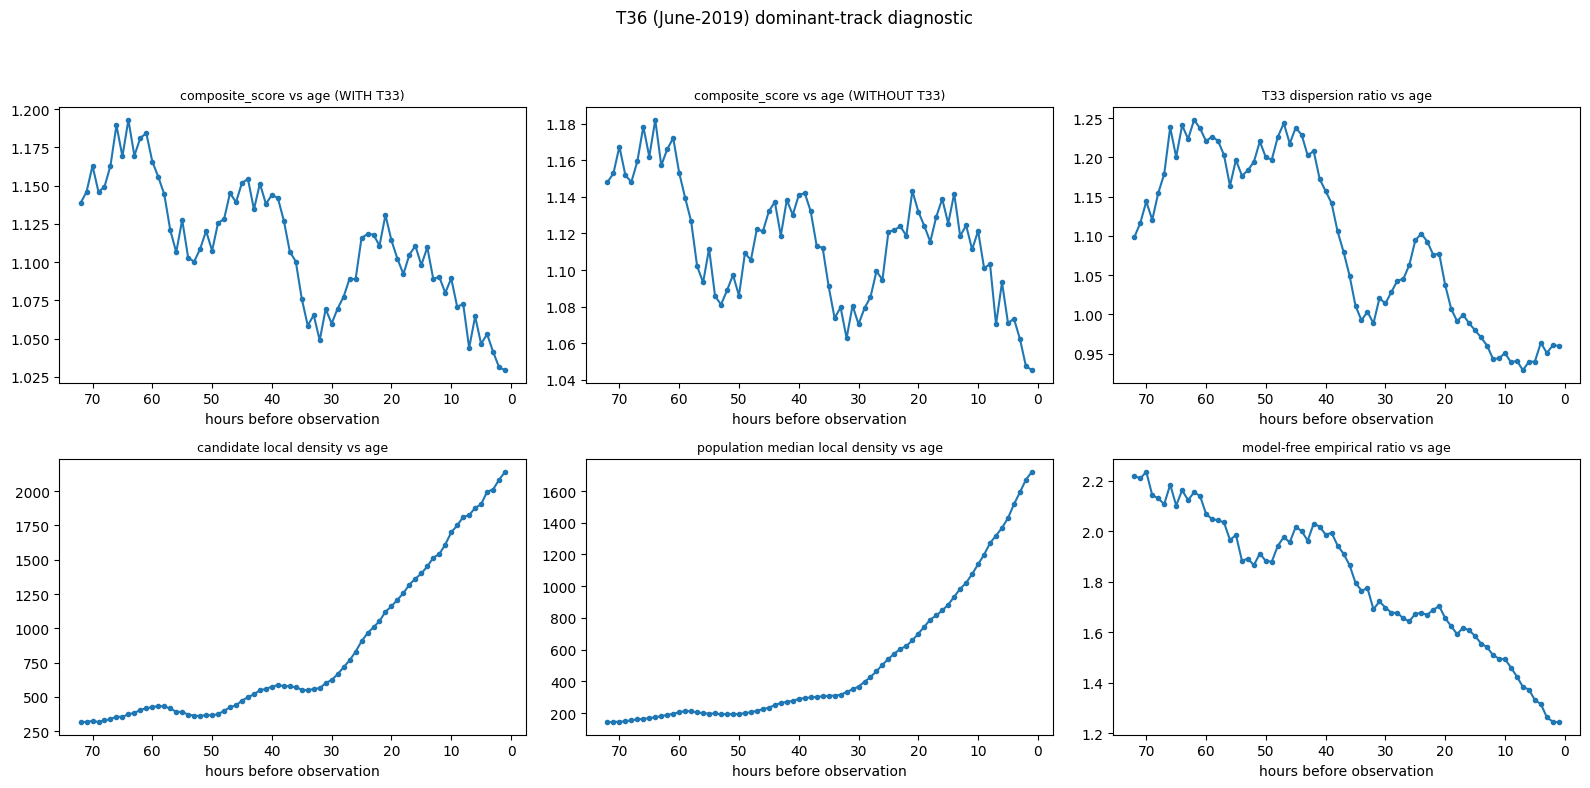

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col, title in [
    (axes[0,0], "composite_score", "composite_score vs age (WITH T33)"),
    (axes[0,1], "composite_score_no_t33", "composite_score vs age (WITHOUT T33)"),
    (axes[0,2], "t33_dispersion_ratio", "T33 dispersion ratio vs age"),
    (axes[1,0], "candidate_local_density", "candidate local density vs age"),
    (axes[1,1], "population_median_local_density", "population median local density vs age"),
    (axes[1,2], "empirical_ratio", "model-free empirical ratio vs age"),
]:
    ax.plot(track_df["age_hours"], track_df[col], "-o", markersize=3)
    ax.set_xlabel("hours before observation"); ax.set_title(title, fontsize=9)
    ax.invert_xaxis()
fig.suptitle("T36 (June-2019) dominant-track diagnostic", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(RESULT_DIR, "T36_dominant_track_diagnostic.png"), dpi=100)
plt.show()

## T37 -- spatial clustering

T37: 271 candidates -> 4 clusters


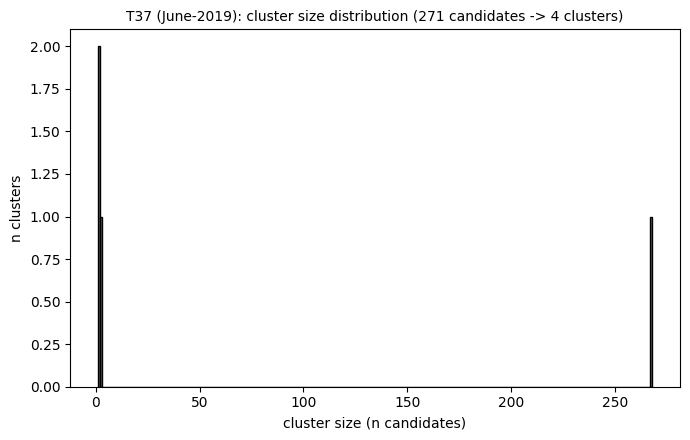

In [30]:
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
print(f"T37: {len(all_candidates)} candidates -> {len(clusters)} clusters")
top10_clusters = clusters[:10]

cluster_sizes = [cl.n_members for cl in clusters]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(cluster_sizes, bins=range(1, max(cluster_sizes) + 2), edgecolor="black")
ax.set_xlabel("cluster size (n candidates)"); ax.set_ylabel("n clusters")
ax.set_title(f"T37 (June-2019): cluster size distribution ({len(all_candidates)} candidates -> {len(clusters)} clusters)", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T37_cluster_size_distribution.png"), dpi=100)
plt.show()

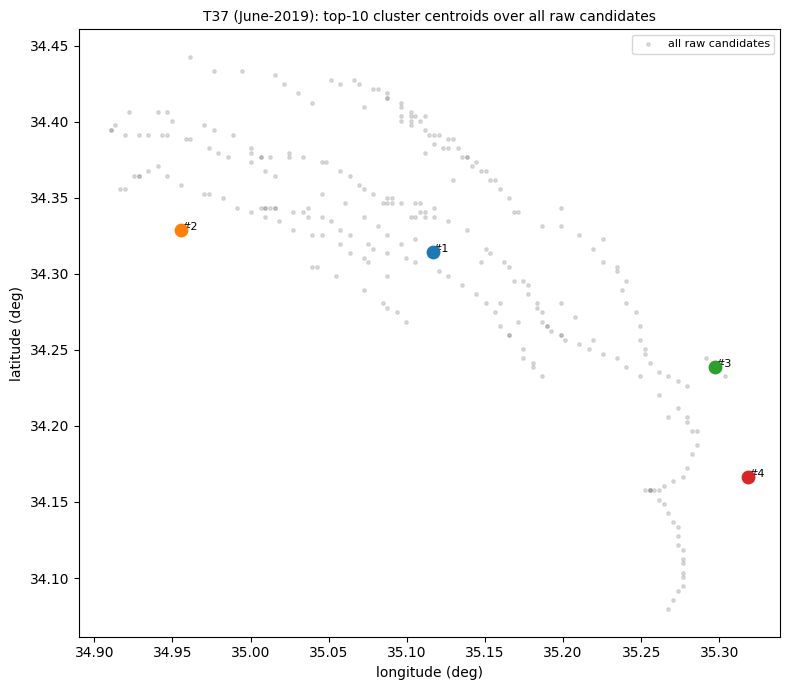

In [31]:
fig, ax = plt.subplots(figsize=(8, 7))
all_lats = [c.y_peak for c in all_candidates]
all_lons = [c.x_peak for c in all_candidates]
ax.scatter(all_lons, all_lats, s=6, alpha=0.25, color="gray", label="all raw candidates")
for rank, cl in enumerate(top10_clusters):
    ax.scatter([cl.centroid_lon], [cl.centroid_lat], s=80, zorder=5)
    ax.annotate(f"#{rank+1}", (cl.centroid_lon, cl.centroid_lat), fontsize=8)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title("T37 (June-2019): top-10 cluster centroids over all raw candidates", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T37_top10_clusters_map.png"), dpi=100)
plt.show()

## T38 -- uncertainty / bootstrap stability

In [32]:
bootstrap_config = BootstrapConfig(n_replicates=200, random_seed=42, top_k=10)
bootstrap_result = run_bootstrap_stability(all_candidates, default_scores, clusters, config=bootstrap_config)
uncertainty_table = compute_cluster_uncertainty_table(
    clusters, all_candidates, default_scores, records,
    total_timestamps=DEFAULT_TOTAL_TIMESTAMPS, spatial_percentile=DEFAULT_SPATIAL_PERCENTILE,
    bootstrap_result=bootstrap_result,
)
print(f"T38: computed uncertainty for {len(uncertainty_table)} clusters (bootstrap runtime {bootstrap_result.runtime_seconds:.2f}s)")

T38: computed uncertainty for 4 clusters (bootstrap runtime 10.71s)


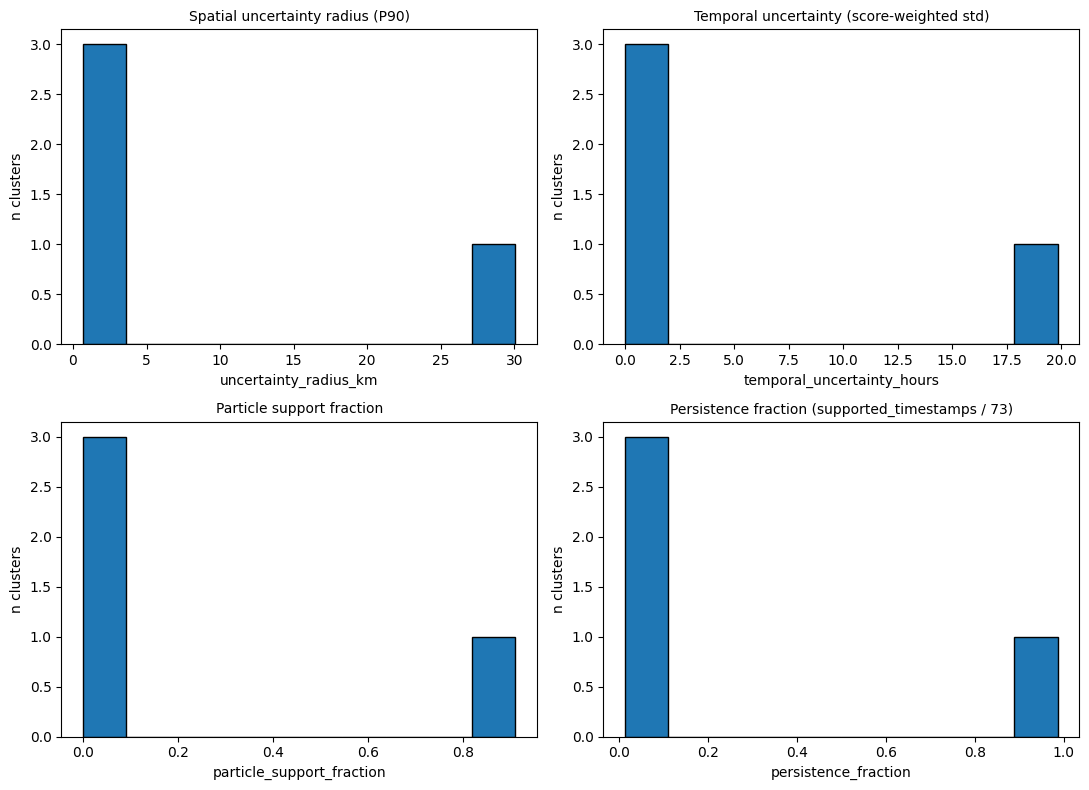

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
vals = [r.uncertainty_radius_km for r in uncertainty_table if np.isfinite(r.uncertainty_radius_km)]
axes[0, 0].hist(vals, bins=10, edgecolor="black")
axes[0, 0].set_xlabel("uncertainty_radius_km"); axes[0, 0].set_ylabel("n clusters")
axes[0, 0].set_title(f"Spatial uncertainty radius (P{DEFAULT_SPATIAL_PERCENTILE:.0f})", fontsize=10)
vals = [r.temporal_uncertainty_hours for r in uncertainty_table]
axes[0, 1].hist(vals, bins=10, edgecolor="black")
axes[0, 1].set_xlabel("temporal_uncertainty_hours"); axes[0, 1].set_ylabel("n clusters")
axes[0, 1].set_title("Temporal uncertainty (score-weighted std)", fontsize=10)
vals = [r.particle_support_fraction for r in uncertainty_table]
axes[1, 0].hist(vals, bins=10, edgecolor="black")
axes[1, 0].set_xlabel("particle_support_fraction"); axes[1, 0].set_ylabel("n clusters")
axes[1, 0].set_title("Particle support fraction", fontsize=10)
vals = [r.persistence_fraction for r in uncertainty_table]
axes[1, 1].hist(vals, bins=10, edgecolor="black")
axes[1, 1].set_xlabel("persistence_fraction"); axes[1, 1].set_ylabel("n clusters")
axes[1, 1].set_title("Persistence fraction (supported_timestamps / 73)", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T38_uncertainty_distributions.png"), dpi=100)
plt.show()

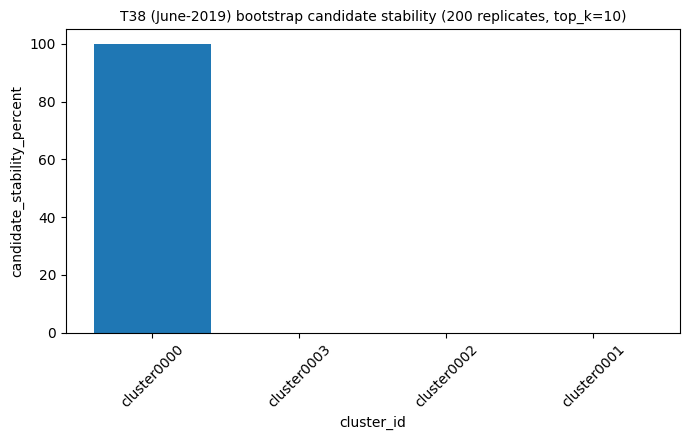

In [34]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([r.cluster_id for r in uncertainty_table], [r.candidate_stability_percent or 0.0 for r in uncertainty_table])
ax.set_xlabel("cluster_id"); ax.set_ylabel("candidate_stability_percent")
ax.set_title(f"T38 (June-2019) bootstrap candidate stability ({bootstrap_config.n_replicates} replicates, top_k={bootstrap_config.top_k})", fontsize=10)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T38_bootstrap_stability.png"), dpi=100)
plt.show()

n_clusters=4
spearman(age, uncertainty_radius_km)=0.4000
spearman(age, temporal_uncertainty_hours)=0.4000
spearman(spread, uncertainty_radius_km)=1.0000


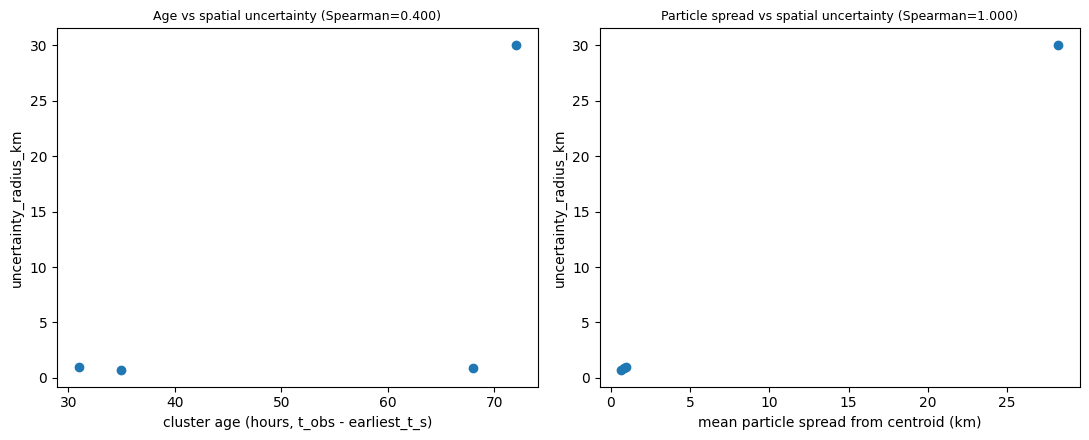

In [35]:
age_diag = diagnose_uncertainty_vs_age(clusters, uncertainty_table, all_candidates, t_obs)
print(f"n_clusters={age_diag.n_clusters}")
print(f"spearman(age, uncertainty_radius_km)={age_diag.spearman_age_vs_uncertainty_radius:.4f}")
print(f"spearman(age, temporal_uncertainty_hours)={age_diag.spearman_age_vs_temporal_uncertainty:.4f}")
print(f"spearman(spread, uncertainty_radius_km)={age_diag.spearman_spread_vs_uncertainty_radius:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(age_diag.age_hours, age_diag.uncertainty_radius_km)
axes[0].set_xlabel("cluster age (hours, t_obs - earliest_t_s)"); axes[0].set_ylabel("uncertainty_radius_km")
axes[0].set_title(f"Age vs spatial uncertainty (Spearman={age_diag.spearman_age_vs_uncertainty_radius:.3f})", fontsize=9)
axes[1].scatter(age_diag.mean_particle_spread_km, age_diag.uncertainty_radius_km)
axes[1].set_xlabel("mean particle spread from centroid (km)"); axes[1].set_ylabel("uncertainty_radius_km")
axes[1].set_title(f"Particle spread vs spatial uncertainty (Spearman={age_diag.spearman_spread_vs_uncertainty_radius:.3f})", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T38_age_vs_uncertainty_diagnostic.png"), dpi=100)
plt.show()

dominant cluster: cluster0000, n_members=267, spatial_radius_km=29.56, uncertainty_radius_km=30.07


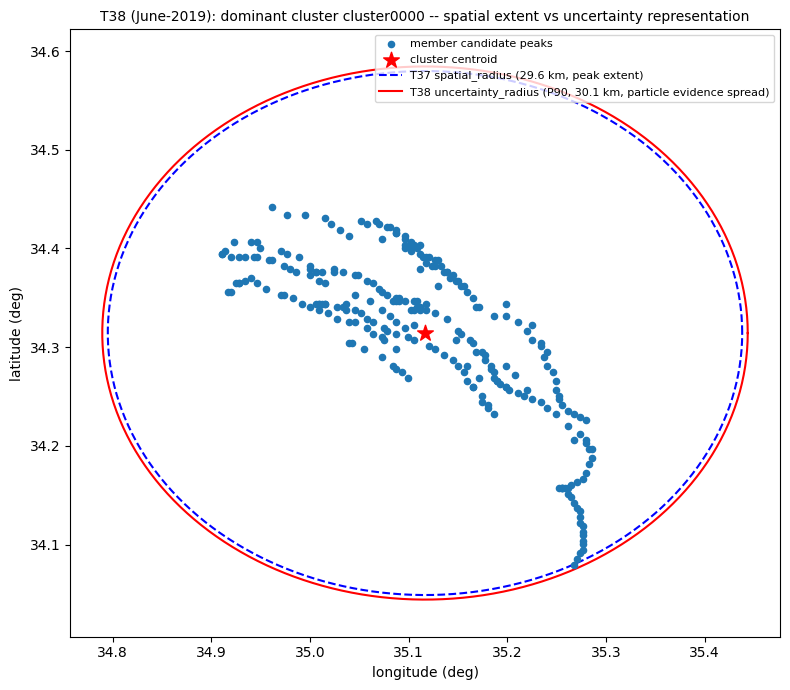

In [36]:
dominant = max(clusters, key=lambda cl: cl.n_members)
dominant_row = next(r for r in uncertainty_table if r.cluster_id == dominant.cluster_id)
print(f"dominant cluster: {dominant.cluster_id}, n_members={dominant.n_members}, "
      f"spatial_radius_km={dominant_row.spatial_radius_km:.2f}, uncertainty_radius_km={dominant_row.uncertainty_radius_km:.2f}")

member_ids = set(dominant.member_candidate_ids)
member_cands = [c for c in all_candidates if c.candidate_id in member_ids]

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter([c.x_peak for c in member_cands], [c.y_peak for c in member_cands],
           s=20, c="tab:blue", label="member candidate peaks", zorder=5)
ax.scatter([dominant.centroid_lon], [dominant.centroid_lat], s=140, marker="*", c="red",
           label="cluster centroid", zorder=6)

theta = np.linspace(0, 2 * np.pi, 200)
def _circle_lonlat(radius_m, lat_ref, lon_ref):
    x_m = radius_m * np.cos(theta); y_m = radius_m * np.sin(theta)
    dlat = y_m / 111320.0
    dlon = x_m / (111320.0 * np.cos(np.radians(lat_ref)))
    return lon_ref + dlon, lat_ref + dlat

lon_c, lat_c = _circle_lonlat(dominant.spatial_radius_m, dominant.centroid_lat, dominant.centroid_lon)
ax.plot(lon_c, lat_c, "b--", linewidth=1.5, label=f"T37 spatial_radius ({dominant.spatial_radius_m/1000:.1f} km, peak extent)")
lon_u, lat_u = _circle_lonlat(dominant_row.uncertainty_radius_km * 1000.0, dominant.centroid_lat, dominant.centroid_lon)
ax.plot(lon_u, lat_u, "r-", linewidth=1.5, label=f"T38 uncertainty_radius (P{DEFAULT_SPATIAL_PERCENTILE:.0f}, {dominant_row.uncertainty_radius_km:.1f} km, particle evidence spread)")

ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"T38 (June-2019): dominant cluster {dominant.cluster_id} -- spatial extent vs uncertainty representation", fontsize=10)
ax.legend(fontsize=8, loc="best")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "T38_dominant_cluster_uncertainty.png"), dpi=100)
plt.show()

## Validation

In [37]:
expected_pngs = [
    "T28_diagnostics_t0_t72.png", "T29_raw_vs_normalized_kde.png", "T30_initial_bias_influence.png",
    "T31_persistence_tracks.png", "T31_longest_track.png", "T31_displacement_distribution.png", "T31_longest_track_annotated.png",
    "T32_convergence_components.png", "T32_correlation_matrices.png", "T32_ablation_top15_stacked.png",
    "T33_dispersion_vs_raw.png", "T33_anisotropy_characterization.png", "T33_isotropic_vs_anisotropic.png", "T33_empirical_null_diagnostic.png",
    "T34_screening_normalization.png", "T36_composite_vs_raw_support.png", "T36_dominant_track_diagnostic.png",
    "T37_cluster_size_distribution.png", "T37_top10_clusters_map.png",
    "T38_uncertainty_distributions.png", "T38_bootstrap_stability.png", "T38_age_vs_uncertainty_diagnostic.png", "T38_dominant_cluster_uncertainty.png",
]
missing = [f for f in expected_pngs if not os.path.exists(os.path.join(RESULT_DIR, f))]
print(f"expected {len(expected_pngs)} per-task diagnostic PNGs; missing: {missing if missing else 'NONE'}")
assert not missing
print("all per-task diagnostic PNGs successfully regenerated for the June-2019 event under result/")

expected 23 per-task diagnostic PNGs; missing: NONE
all per-task diagnostic PNGs successfully regenerated for the June-2019 event under result/
